Exercice 3 : Apprentissage d'un CNN sur le dataset MNIST

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, Input
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import pandas as pd

In [2]:
(X_train_raw, y_train), (X_test_raw, y_test) = datasets.mnist.load_data()

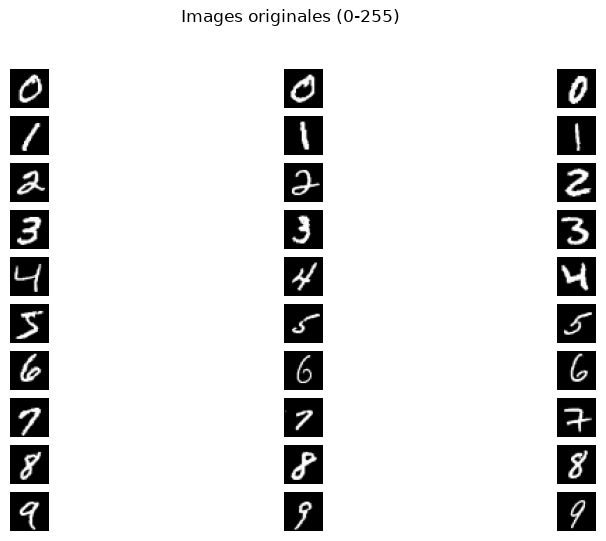

In [3]:
plt.figure(figsize=(10, 6))
for digit in range(10):
    idx = np.where(y_train == digit)[0][:3]  # Trouver l'index du premier exemple du chiffre
    for i, j in enumerate(idx):
        plt.subplot(10, 3, digit*3 + i + 1)
        plt.imshow(X_train_raw[j], cmap='gray')
        plt.axis('off')
plt.suptitle("Images originales (0-255)")
plt.show()

In [4]:
X_train = X_train_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

In [5]:
X_train = np.expand_dims(X_train, -1)  # Ajouter une dimension pour le canal
X_test = np.expand_dims(X_test, -1)  # Ajouter une dimension pour le canal

print("Formes finales :", X_train.shape, X_test.shape)

Formes finales : (60000, 28, 28, 1) (10000, 28, 28, 1)


In [7]:
model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

In [8]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 17ms/step - accuracy: 0.9167 - loss: 0.2639 - val_accuracy: 0.9840 - val_loss: 0.0561
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.9769 - loss: 0.0783 - val_accuracy: 0.9875 - val_loss: 0.0432
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9842 - loss: 0.0540 - val_accuracy: 0.9892 - val_loss: 0.0400
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9866 - loss: 0.0426 - val_accuracy: 0.9890 - val_loss: 0.0387
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.9895 - loss: 0.0350 - val_accuracy: 0.9903 - val_loss: 0.0392


In [ ]:
loss, acc = model.evaluate(X_test, y_test, verbose=2)
print(f"Test Loss: {loss:.4f}, Test Accuracy: {acc:.4f}")

313/313 - 1s - 4ms/step - accuracy: 0.9920 - loss: 0.0271
Test Loss: 0.0271, Test Accuracy: 0.9920


In [12]:
y_pred = np.argmax(model.predict(X_test), axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


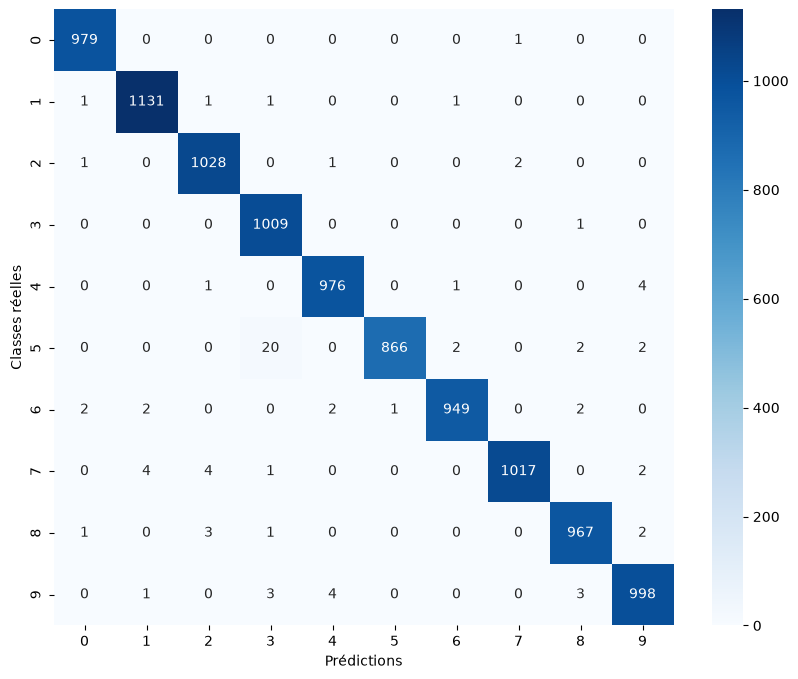

In [13]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Prédictions')
plt.ylabel('Classes réelles')
plt.show()

In [14]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00       980
           1       0.99      1.00      1.00      1135
           2       0.99      1.00      0.99      1032
           3       0.97      1.00      0.99      1010
           4       0.99      0.99      0.99       982
           5       1.00      0.97      0.98       892
           6       1.00      0.99      0.99       958
           7       1.00      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



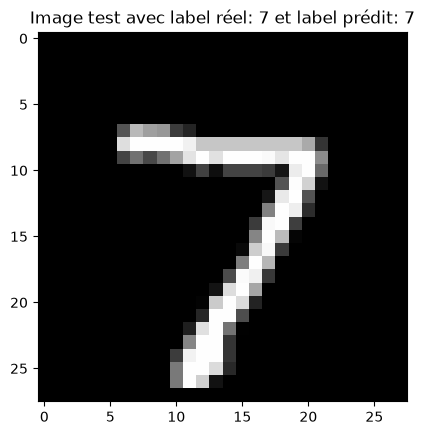

In [15]:
plt.imshow(X_test[0].reshape(28, 28), cmap='gray')
plt.title(f"Image test avec label réel: {y_test[0]} et label prédit: {y_pred[0]}")
plt.show()

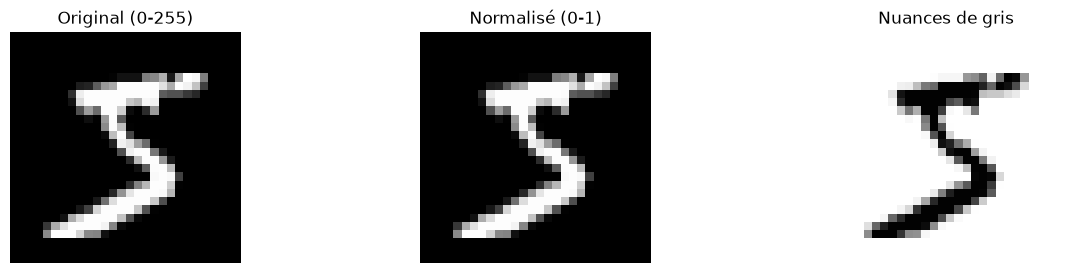

In [17]:
img = X_train_raw[y_train == 5][0]  # Exemple d'image du chiffre 5
plt.figure(figsize=(15,3))
plt.subplot(1,3,1)
plt.imshow(img, cmap='gray')
plt.title("Original (0-255)")
plt.axis('off')

img_norm = img.astype("float32") / 255.0
plt.subplot(1,3,2)
plt.imshow(img_norm, cmap='gray')
plt.title("Normalisé (0-1)")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(img_norm, cmap='Greys')
plt.title("Nuances de gris")
plt.axis('off')

plt.show()

2ème étude : Explication du code

Du code utilisé précédemment, on ne gardera que ce qui est nécessaire aux traitements, en excluant les affichages.

Extraction des données d'entraînement et de test :

In [ ]:
(X_train_raw, y_train), (X_test_raw, y_test) = datasets.mnist.load_data()

Normalisation des données d'entrée pour les placer entre 0 et 1 :

In [ ]:
X_train = X_train_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

On rajoute un canal pour le niveau de gris, nécessaire avec Conv2D :

In [ ]:
X_train = np.expand_dims(X_train, -1)  # Ajouter une dimension pour le canal
X_test = np.expand_dims(X_test, -1)  # Ajouter une dimension pour le canal

Déclaration du modèle, cf. powerpoint :

In [ ]:
model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

loss='sparse_categorical_crossentropy' : c'est la fonction que le réseau cherche à minimiser pour apprendre
metrics=['accuracy'] : c'est une mesure utilisée pour observer et évaluer les performances du réseau 

Le modèle apprend en essayant de diminuer la loss, pas directement en essayant d'augmenter l'accuracy

In [ ]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

Lancement de l'entraînement, 5 itérations sur l'ensemble des données, correction des paramètres toutes les 64 données, 10% des données d'entraînement réservées à la validation :

In [ ]:
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

Lancement des tests : calcul du loss et de l'accuracy

In [ ]:
loss, acc = model.evaluate(X_test, y_test, verbose=2)

Calcul des prédiction à partir des données de test :

In [ ]:
y_pred = np.argmax(model.predict(X_test), axis=1)

Comparaison des données prédites et des données attendues pour les tests : plus la matrice est diagonale, mieux c'est

In [ ]:
cm = confusion_matrix(y_test, y_pred)